# DBSCAN — Step-by-Step Python Notebook
**Datasets:** Two Moons (clear visual demonstration) and Wine (standard scikit-learn dataset).

**Aim:** Learn how `eps` and `min_samples` influence clustering, and identify noise points (`-1`).
No external files or downloads are needed.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

## 2. Dataset A — Two Moons
This dataset contains two curved groups. It is easier to understand DBSCAN here than on a high-dimensional dataset.

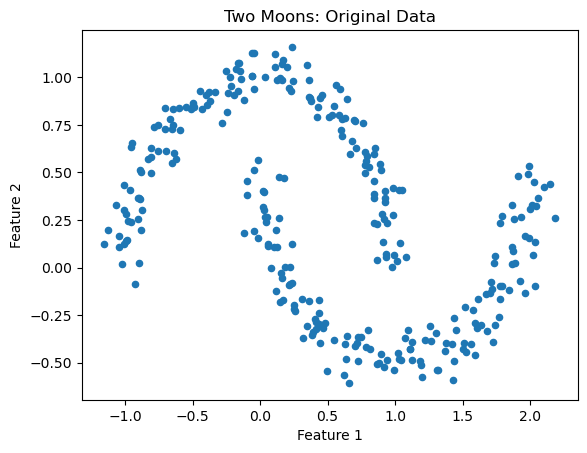

In [2]:
X_moons, _ = make_moons(n_samples=300, noise=0.07, random_state=42)

plt.scatter(X_moons[:, 0], X_moons[:, 1], s=20)
plt.title("Two Moons: Original Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## 3. Train DBSCAN
- `eps`: neighbourhood radius
- `min_samples`: minimum number of samples in the neighbourhood **including the point itself** for a core point
- Label `-1` means a sample is classified as noise.

In [8]:
dbscan = DBSCAN(eps=0.10, min_samples=5)
labels = dbscan.fit_predict(X_moons)

print("Cluster labels and counts:")
print(pd.Series(labels).value_counts().sort_index())

Cluster labels and counts:
-1     47
 0     54
 1     47
 2     13
 3      9
 4     16
 5      9
 6     50
 7     11
 8     14
 9     20
 10    10
Name: count, dtype: int64


## 4. Plot the clusters

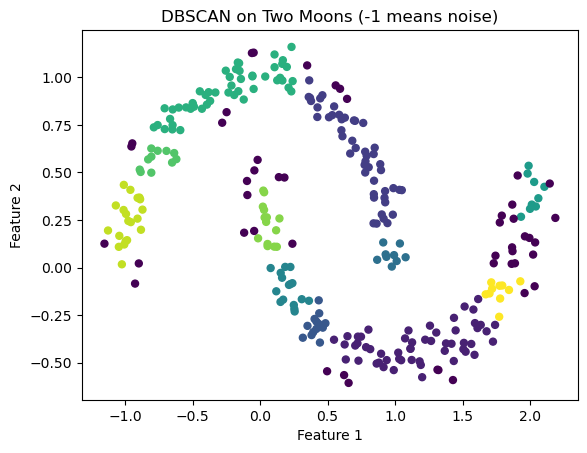

In [9]:
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap="viridis", s=25)
plt.title("DBSCAN on Two Moons (-1 means noise)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## 5. Optional: k-distance plot to help choose `eps`
For `min_samples=5`, calculate the distance to each point's **5th nearest neighbour (counting itself)**. A bend in the sorted curve can be a starting point for trying `eps`; it is not an automatic or exact rule.

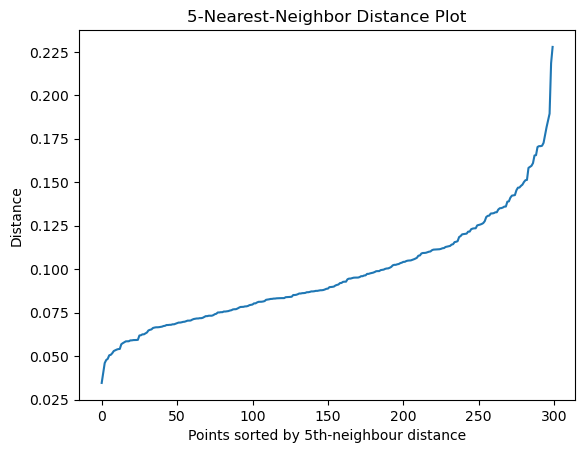

In [5]:
neighbors = NearestNeighbors(n_neighbors=5).fit(X_moons)
distances, _ = neighbors.kneighbors(X_moons)
k_distances = np.sort(distances[:, -1])

plt.plot(k_distances)
plt.xlabel("Points sorted by 5th-neighbour distance")
plt.ylabel("Distance")
plt.title("5-Nearest-Neighbor Distance Plot")
plt.show()

## 6. Dataset B — Wine (13 features)
Standardize features before applying distance-based clustering. DBSCAN may find a different number of clusters than the Wine dataset's three known classes; that is expected.

In [35]:
wine = load_wine(as_frame=True)
X = wine.data
X_scaled = StandardScaler().fit_transform(X)

wine_dbscan = DBSCAN(eps=2.9, min_samples=4)
wine_labels = wine_dbscan.fit_predict(X_scaled)

print("Clusters and noise counts:")
print(pd.Series(wine_labels).value_counts().sort_index())

Clusters and noise counts:
-1     12
 0    166
Name: count, dtype: int64


## 7. Visualize Wine clusters using PCA
PCA reduces 13 features to two components **only for plotting**. DBSCAN above used all 13 scaled features.

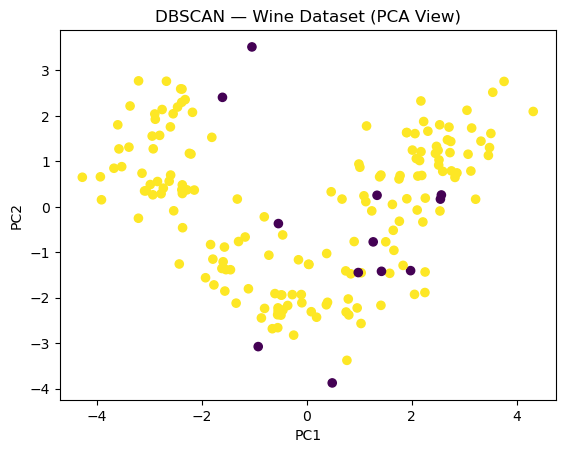

In [36]:
X_pca = PCA(n_components=2).fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=wine_labels, cmap="viridis", s=35)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN — Wine Dataset (PCA View)")
plt.show()

## Student exercises
1. Change Two Moons `eps` from `0.20` to `0.10`. What happens to the number of noise points?
2. Change Two Moons `min_samples` from `5` to `10`. What changes?
3. Change Wine `eps` to `2.0` and `3.0` and compare the cluster and noise counts.
4. Why is the Wine PCA plot only an approximation of separation in 13-dimensional space?